In [1]:
SID4 = 5330
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
print(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}")

SID4=5330 SEED=5330 SLICE=330 HP_ID=2 CLS_A=0 CLS_B=3


# Assignment 7: GANs and AutoEncoders on FashionMNIST

Only SEED is used. No second hyperparameter configuration is trained, since this assignment already compares two models.

## 1a. GAN Architecture

A GAN has two neural networks trained against each other.

**Generator G.** Takes a random noise vector z (for example from a Gaussian) and maps it to a fake sample G(z), such as an image. It never sees real data directly. It learns only from the feedback the discriminator gives it.

**Discriminator D.** A binary classifier that takes a sample and outputs the probability that it is real (from the dataset) rather than fake (from G).

**Training interaction.** The two networks take turns:

1. Update D: show it a batch of real images labeled 1 and a batch of G(z) labeled 0, and step D to classify them correctly.
2. Update G: generate a batch, pass it through D, and step G so that D labels the fakes as real. The gradient flows back through D into G, telling G how to change its output to look more real.

This is a two player min max game:

min over G, max over D of  E[log D(x)] + E[log(1 minus D(G(z)))]

In practice G maximizes log D(G(z)) instead (the non saturating loss), because it gives stronger gradients early in training when D easily rejects the fakes.

**Theoretical goal.** For a fixed G the best discriminator is D*(x) = p_data(x) / (p_data(x) + p_g(x)). Plugging that in, G is minimizing the Jensen Shannon divergence between the real distribution p_data and the generated distribution p_g. The global optimum is a Nash equilibrium where p_g = p_data, so D cannot do better than guessing and outputs 0.5 everywhere. At that point G produces samples indistinguishable from real data.

## 1b. Mode Collapse

**Definition.** Mode collapse happens when the generator produces only a small set of very similar outputs and ignores many modes of the real data. For example, on FashionMNIST it might only produce shirts, or the same sneaker over and over, no matter what z is.

**Why it occurs.** The generator is rewarded only for fooling the current discriminator, not for covering the whole data distribution. If one output fools D well, G can map many different z values to it. D then learns to reject that output, G jumps to another single mode, and the two chase each other instead of converging. Nothing in the original loss directly penalizes low diversity, and the alternating gradient updates mean G optimizes against a moving target rather than the true min max solution. The Jensen Shannon loss also gives vanishing gradients when the two distributions barely overlap, which makes the instability worse.

**Technique 1: Wasserstein GAN (WGAN, WGAN GP).** Replaces the Jensen Shannon objective with the Earth Mover (Wasserstein 1) distance. The discriminator becomes a critic that outputs an unbounded score instead of a probability, and it is kept 1 Lipschitz using weight clipping or, better, a gradient penalty that pushes the norm of the critic gradient toward 1. *Mechanism:* the Wasserstein distance is smooth and gives useful gradients even when real and fake distributions do not overlap, so the critic can be trained to optimality without the generator gradient vanishing. If G collapses to one mode the distance to the full distribution stays large, so G keeps getting a signal to spread out. The critic loss also correlates with sample quality, making training easier to monitor.

**Technique 2: Minibatch discrimination.** The discriminator looks at a whole batch rather than each sample alone. In the original version (Salimans et al., 2016) the intermediate features of each sample are multiplied by a learned tensor to give a set of vectors, the L1 distances between these vectors and those of every other sample in the batch are passed through a negative exponential and summed, and the result is appended to the sample's features. A related but different and simpler technique is the minibatch standard deviation layer from ProGAN (also used in StyleGAN), which has no learned parameters: it computes the standard deviation of each feature across the batch, averages it to a single number, and appends that as an extra feature map. *Mechanism:* a collapsed generator produces batches with almost no variety, which real batches never have, so D can easily spot them. To fool D, G must produce batches whose diversity matches real data, which directly penalizes collapse.

**Other options.** *Unrolled GANs:* G's loss is computed against a copy of D that has been updated k steps ahead, and the gradient is backpropagated through those steps. G therefore sees how D would react to its move. Collapsing onto one mode only fools D until D adapts, and the unrolled loss already includes that adaptation, so collapsing is no longer rewarded. *Spectral normalization:* every weight matrix of D is divided by its largest singular value (estimated cheaply with power iteration), which caps the Lipschitz constant of D. D then cannot become arbitrarily sharp around the few samples G produces, so its gradients stay smooth and informative and G is not pushed back and forth between modes.

## 1c. GAN Variants

**DCGAN (Deep Convolutional GAN).**
*Problem:* the original GAN used fully connected layers and was very unstable and hard to scale to images.
*Innovations:* a set of architecture rules that made convolutional GANs train reliably. Pooling is replaced with strided convolutions in D and transposed convolutions in G, so the network learns its own up and down sampling. Batch normalization is used in both networks (except the G output and D input). Fully connected hidden layers are removed. G uses ReLU with a Tanh output and D uses LeakyReLU. These choices give stable training, sharper images, and a latent space where vector arithmetic works (for example man with glasses minus man plus woman gives woman with glasses).

**Conditional GAN (cGAN).**
*Problem:* a plain GAN gives no control over what is generated. You cannot ask for a particular class.
*Innovations:* both G and D receive extra information y, such as a class label, usually as an embedding concatenated to z and to the D input. G models p(x given y) and D judges whether the pair (x, y) is real and matching. This lets you generate a chosen class (for example only sandals), and the extra signal often helps stabilize training. It can also reduce collapse across classes, because each label must be produced, although this is not guaranteed: G can still collapse within a class. The same idea underlies pix2pix, which conditions on a whole input image.

**CycleGAN.**
*Problem:* image to image translation (horse to zebra, photo to painting) normally needs paired examples, which often do not exist.
*Innovations:* two generators, G from domain X to Y and F from Y to X, each with its own discriminator. Besides the adversarial losses, it adds a cycle consistency loss: translating an image to the other domain and back should recover the original, so F(G(x)) is close to x and G(F(y)) is close to y (L1 loss). This forces the translation to keep the content and structure of the input while changing only the style, and it works with unpaired image collections. An optional identity loss helps keep colors stable.

## 2. AutoEncoders on FashionMNIST

Both models use the same 784 to 512 to 256 hidden sizes, a 16 dimensional latent space, Adam with learning rate 0.001, batch size 128 and 15 epochs, so the only difference is the latent bottleneck. Pixels are scaled to [0, 1] and the decoders end in a sigmoid, so reconstruction uses binary cross entropy.

In [2]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms as T

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"

train = datasets.FashionMNIST("../data", train=True, download=True, transform=T.ToTensor())
test = datasets.FashionMNIST("../data", train=False, download=True, transform=T.ToTensor())
train_loader = torch.utils.data.DataLoader(train, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(test, batch_size=512)
CLASSES = train.classes
LATENT, EPOCHS = 16, 15
print(len(train), len(test), device)

60000 10000 mps


In [3]:
def mlp(sizes, last=None):
    layers = []
    for a, b in zip(sizes[:-1], sizes[1:]):
        layers += [nn.Linear(a, b), nn.ReLU()]
    layers = layers[:-1]
    if last:
        layers.append(last)
    return nn.Sequential(*layers)


class FCAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = mlp([784, 512, 256, LATENT])
        self.dec = mlp([LATENT, 256, 512, 784], nn.Sigmoid())

    def forward(self, x):
        z = self.enc(x.flatten(1))
        return self.dec(z).view_as(x), z


class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = mlp([784, 512, 256, 2 * LATENT])
        self.dec = mlp([LATENT, 256, 512, 784], nn.Sigmoid())

    def forward(self, x, sample=True):
        mu, logvar = self.enc(x.flatten(1)).chunk(2, 1)
        z = mu + torch.randn_like(mu) * (0.5 * logvar).exp() if sample else mu
        return self.dec(z).view_as(x), mu, logvar


def loss_fn(model, x, sample=True):
    if isinstance(model, VAE):
        xh, mu, logvar = model(x, sample)
        kl = 0.5 * (mu.pow(2) + logvar.exp() - 1 - logvar).sum()
    else:
        xh, _ = model(x)
        kl = torch.tensor(0.0)
    bce = F.binary_cross_entropy(xh, x, reduction="sum")
    return bce + kl, bce, kl, F.mse_loss(xh, x, reduction="sum")


@torch.no_grad()
def evaluate(model, sample=True):
    model.eval()
    tot = np.zeros(4)
    for x, _ in test_loader:
        x = x.to(device)
        tot += [t.item() for t in loss_fn(model, x, sample)]
    return tot / len(test) * np.array([1, 1, 1, 1 / 784])


def fit(model):
    opt = torch.optim.Adam(model.parameters(), 1e-3)
    hist = {"train": [], "test": []}
    for ep in range(EPOCHS):
        model.train()
        run = 0
        for x, _ in train_loader:
            x = x.to(device)
            loss = loss_fn(model, x)[0]
            opt.zero_grad()
            loss.backward()
            opt.step()
            run += loss.item()
        hist["train"].append(run / len(train))
        hist["test"].append(evaluate(model)[0])
        print(f"epoch {ep + 1} train {hist['train'][-1]:.2f} test {hist['test'][-1]:.2f}")
    return hist

### Train FC AE

In [4]:
torch.manual_seed(SEED)
fcae = FCAE().to(device)
h_ae = fit(fcae)

epoch 1 train 264.15 test 238.25


epoch 2 train 231.86 test 230.18


epoch 3 train 226.14 test 225.78


epoch 4 train 222.26 test 222.86


epoch 5 train 219.83 test 220.41


...

epoch 11 train 213.93 test 216.76


epoch 12 train 213.57 test 215.95


epoch 13 train 213.24 test 215.49


epoch 14 train 212.90 test 215.06


epoch 15 train 212.67 test 214.83


### Train VAE

In [5]:
torch.manual_seed(SEED)
vae = VAE().to(device)
h_vae = fit(vae)

epoch 1 train 287.74 test 259.99


epoch 2 train 253.43 test 251.43


epoch 3 train 248.07 test 248.34


epoch 4 train 245.70 test 246.33


epoch 5 train 243.97 test 245.36


...

epoch 11 train 239.94 test 241.67


epoch 12 train 239.59 test 241.71


epoch 13 train 239.29 test 241.50


epoch 14 train 239.10 test 241.18


epoch 15 train 238.81 test 240.68


### Evaluation

model          total       BCE        KL   pixel MSE
FC AE         214.83    214.83      0.00     0.01032
VAE (z)       240.64    228.43     12.21     0.01642
VAE (mu)      237.97    225.75     12.21     0.01524


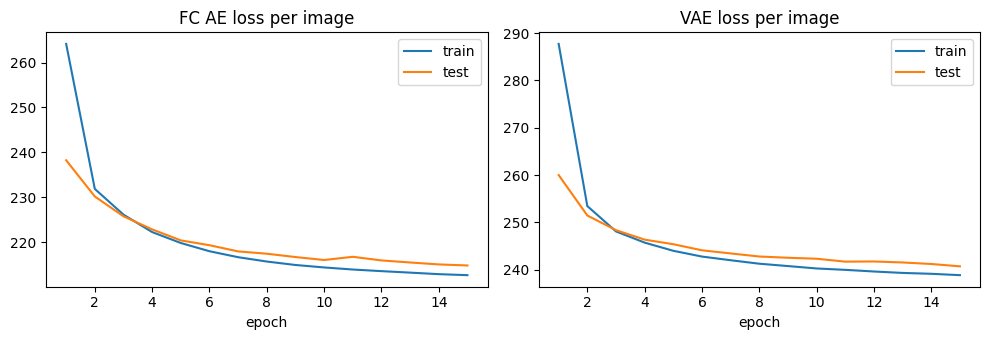

In [6]:
torch.manual_seed(SEED)
res = {"FC AE": evaluate(fcae), "VAE (z)": evaluate(vae), "VAE (mu)": evaluate(vae, sample=False)}
print(f"{'model':10}{'total':>10}{'BCE':>10}{'KL':>10}{'pixel MSE':>12}")
for k, (tot, bce, kl, mse) in res.items():
    print(f"{k:10}{tot:10.2f}{bce:10.2f}{kl:10.2f}{mse:12.5f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, (name, h) in zip(ax, [("FC AE", h_ae), ("VAE", h_vae)]):
    a.plot(range(1, EPOCHS + 1), h["train"], label="train")
    a.plot(range(1, EPOCHS + 1), h["test"], label="test")
    a.set(title=f"{name} loss per image", xlabel="epoch")
    a.legend()
plt.tight_layout()
plt.show()

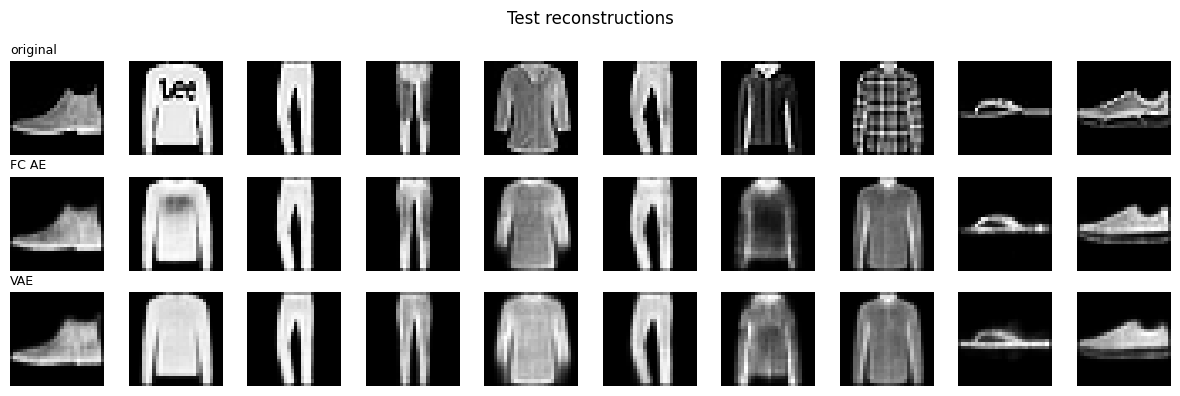

In [7]:
x, y = next(iter(test_loader))
x = x[:10].to(device)
fcae.eval(); vae.eval()
with torch.no_grad():
    rows = [x, fcae(x)[0], vae.dec(vae.enc(x.flatten(1)).chunk(2, 1)[0]).view_as(x)]
fig, ax = plt.subplots(3, 10, figsize=(12, 4))
for r, (name, imgs) in enumerate(zip(["original", "FC AE", "VAE"], rows)):
    for c in range(10):
        ax[r, c].imshow(imgs[c, 0].cpu(), cmap="gray")
        ax[r, c].axis("off")
    ax[r, 0].set_title(name, loc="left", fontsize=9)
plt.suptitle("Test reconstructions")
plt.tight_layout()
plt.show()

FC AE code mean per dim: -2.58 to 3.22, std per dim: 1.71 to 2.94


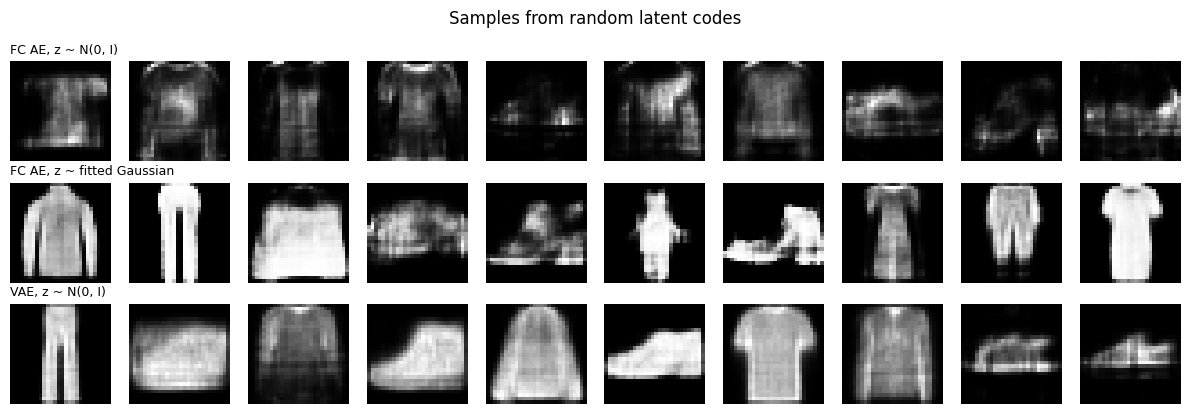

In [8]:
@torch.no_grad()
def codes(model):
    zs, ys = [], []
    for x, y in test_loader:
        out = model.enc(x.to(device).flatten(1))
        zs.append(out[:, :LATENT].cpu())
        ys.append(y)
    return torch.cat(zs), torch.cat(ys)

# Gaussian fitted to the FC AE test codes, so its samples come from the right region and scale
z_ae, _ = codes(fcae)
fitted = torch.distributions.MultivariateNormal(z_ae.mean(0), torch.cov(z_ae.T))
print(f"FC AE code mean per dim: {z_ae.mean(0).min():.2f} to {z_ae.mean(0).max():.2f}, std per dim: {z_ae.std(0).min():.2f} to {z_ae.std(0).max():.2f}")

torch.manual_seed(SEED)
z = torch.randn(10, LATENT, device=device)
z_fit = fitted.sample((10,)).to(device)
with torch.no_grad():
    gens = [fcae.dec(z), fcae.dec(z_fit), vae.dec(z)]
names = ["FC AE, z ~ N(0, I)", "FC AE, z ~ fitted Gaussian", "VAE, z ~ N(0, I)"]
fig, ax = plt.subplots(3, 10, figsize=(12, 4.2))
for r, (name, imgs) in enumerate(zip(names, gens)):
    for c in range(10):
        ax[r, c].imshow(imgs[c].view(28, 28).cpu(), cmap="gray")
        ax[r, c].axis("off")
    ax[r, 0].set_title(name, loc="left", fontsize=9)
plt.suptitle("Samples from random latent codes")
plt.tight_layout()
plt.show()

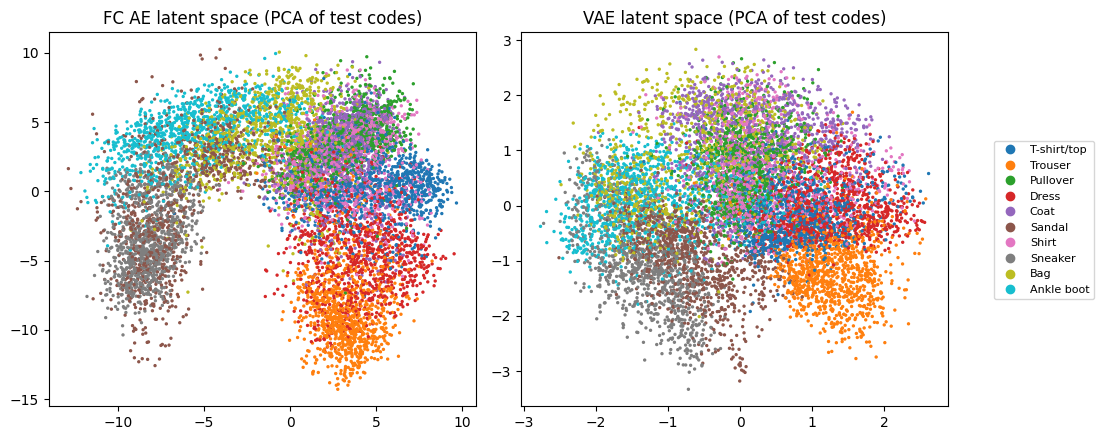

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (name, m) in zip(ax, [("FC AE", fcae), ("VAE", vae)]):
    z, y = codes(m)
    z = z - z.mean(0)
    p = z @ torch.linalg.svd(z, full_matrices=False)[2][:2].T
    s = a.scatter(p[:, 0], p[:, 1], c=y, cmap="tab10", s=2)
    a.set_title(f"{name} latent space (PCA of test codes)")
fig.legend(s.legend_elements()[0], CLASSES, loc="center right", fontsize=8)
plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

total KL 12.21 nats, active dims (KL > 0.1): 6 of 16
sorted KL per dim: 2.76 2.69 2.06 1.98 1.41 1.30 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00


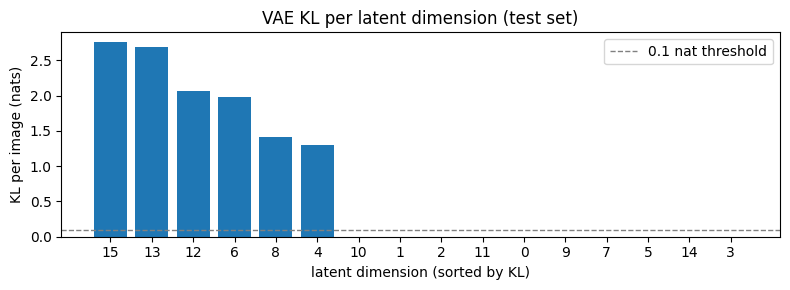

In [10]:
@torch.no_grad()
def kl_per_dim(model):
    tot = torch.zeros(LATENT)
    for x, _ in test_loader:
        mu, logvar = model.enc(x.to(device).flatten(1)).chunk(2, 1)
        tot += (0.5 * (mu.pow(2) + logvar.exp() - 1 - logvar)).sum(0).cpu()
    return tot / len(test)

kl_d = kl_per_dim(vae)
order = kl_d.argsort(descending=True)
active = (kl_d > 0.1).sum().item()
print(f"total KL {kl_d.sum():.2f} nats, active dims (KL > 0.1): {active} of {LATENT}")
print("sorted KL per dim:", " ".join(f"{v:.2f}" for v in kl_d[order]))

plt.figure(figsize=(8, 3))
plt.bar(range(LATENT), kl_d[order])
plt.axhline(0.1, color="gray", ls="--", lw=1, label="0.1 nat threshold")
plt.xticks(range(LATENT), order.tolist())
plt.xlabel("latent dimension (sorted by KL)")
plt.ylabel("KL per image (nats)")
plt.title("VAE KL per latent dimension (test set)")
plt.legend()
plt.tight_layout()
plt.show()

## Analysis

| Model | Test loss per image | BCE | KL | Pixel MSE |
|---|---|---|---|---|
| FC AE | 214.83 | 214.83 | 0.00 | **0.01032** |
| VAE, decoded from sampled z | 240.64 | 228.43 | 12.21 | 0.01642 |
| VAE, decoded from μ | 237.97 | 225.75 | 12.21 | 0.01524 |

Only the BCE and pixel MSE columns compare the models directly. The FC AE "total" is a plain reconstruction loss, while the VAE total is the negative ELBO (BCE plus KL), so the two totals measure different things. The VAE row decoded from μ matches the reconstruction figure, which also decodes μ. The sampled z row matches the training objective and includes sampling noise.

**Reconstruction.** The FC AE reconstructs better: pixel MSE 0.0103 against 0.0152 for the VAE decoded from μ (0.0164 with sampled z). Its only goal is reconstruction, so it can use all 16 latent dimensions freely. The VAE pays a KL cost of about 12 nats per image to keep its codes close to N(0, I), so its reconstructions are blurrier. Fine detail like the "Lee" logo and the plaid pattern is lost by both models, since a 16 dimensional fully connected bottleneck keeps mainly the overall shape.

**Posterior collapse.** The per dimension KL plot shows that only 6 of the 16 VAE latent dimensions carry information (KL between 1.3 and 2.8 nats each). The other 10 have KL of essentially 0, so the encoder outputs μ ≈ 0 and σ ≈ 1 for them whatever the input, and the decoder ignores them. This is partial posterior collapse: the KL penalty makes it cheaper to switch a dimension off than to use it for a small gain in reconstruction. It is one more reason the VAE reconstructs worse than the FC AE, which uses all 16 dimensions. The VAE effectively has a 6 dimensional code.

**Generation.** Decoding z ~ N(0, I) with the VAE gives recognizable trousers, a bag, pullovers, an ankle boot, sneakers, a T shirt and sandals. The same z through the FC AE decoder gives noisy, broken shapes. That comparison is unfair to the FC AE, because its codes have a mean of −2.6 to 3.2 and a standard deviation of 1.7 to 2.9 per dimension, so N(0, I) samples land in a region the decoder never saw. Sampling the FC AE from a Gaussian fitted to its own test codes (empirical mean and covariance) is the fair test. That gives mostly recognizable items as well (trousers, a sneaker, a dress, T shirts), but a few samples are still smeared mixtures of classes. A single Gaussian is a poor fit to the FC AE's horseshoe shaped code distribution, so some samples fall in its empty middle. Most of the original gap was a scale mismatch. The rest comes from the latent structure: the VAE's prior is known in advance and its codes fill it, so N(0, I) samples work without fitting anything, while the FC AE's code density has holes that a simple distribution cannot model.

**Latent space.** The PCA plots show both models place related classes near each other (trousers, footwear, tops, bags), but classes still overlap heavily in both spaces, especially T shirt, shirt, pullover, coat and dress. The FC AE codes cover a large region (about ±10) in a horseshoe shape with an empty area in the middle. The VAE codes sit in a compact, roughly round region around the origin with no large holes, which is why sampling from and interpolating in it works.

**Training.** Train and test loss stay close for both models, so neither overfits in 15 epochs. Both curves fall steadily, apart from a small rise in the FC AE test loss at epoch 11 (216.05 to 216.76) that recovers the next epoch. The FC AE converges to a lower loss, as expected since it has no KL term.

**Conclusion.** The FC AE is the better compressor. The VAE is the better generative model, but by a smaller margin than naive N(0, I) sampling suggests: its advantage is that it generates well from a known, simple prior with no fitting step. A convolutional encoder and decoder or more epochs would sharpen both. A lower KL weight (β < 1) would probably activate more VAE dimensions and improve its reconstructions, at some cost to sample quality.